# Exercise 1: From municipalities to counties

Each Norwegian municipality (*kommune*) belongs to a county (*fylke*). In this
exercise, you will use municipality-level data from Statistics Norway (SSB) to
compare counties by their number of municipalities, population, and population
density.

1.  Load `municipalities.csv` from the `data/ssb/` folder. Keep only the columns
    `municipality`, `county`, `population`, and `land_area`, and display the first
    five rows.

    Each row represents one municipality. The column `population` records its
    number of residents, and `land_area` records its land area in km².

2.  Group the data by `county` and count the municipalities in each county.
    Display the counts in descending order. Which county contains the most
    municipalities?

    *Hint:* Applying `size()` to a grouped DataFrame counts the rows in each group.

3.  Create a DataFrame named `df_counties` containing the total population and
    total land area of each county. Report the three counties with the largest
    populations.

    Check that summing the county populations gives the same national total as
    summing the municipality populations.

4.  Add a column named `density` to `df_counties`, containing each county's
    population density in residents per km² of land:

    $$
    \text{Population density} =
    \frac{\text{Total population}}{\text{Total land area}}
    $$

    Report the three counties with the highest population densities. Does the
    county with the largest population also have the highest population density?

In [76]:
import pandas as pd

DATA_PATH = '../../data'
file = f'{DATA_PATH}/ssb/municipalities.csv'
df_muni = pd.read_csv(file, sep=',')

columns = ['municipality', 'county', 'population', 'land_area']
df_muni = df_muni[columns]

# Tabulate the first 5 rows (default is 5)
df_muni.head()

,municipality,county,population,land_area
0,Oslo,Oslo,724290,426
1,Bergen,Vestland,293709,445
2,Trondheim - Tråante,Trøndelag - Trööndelage,216518,496
3,Stavanger,Rogaland,150123,256
4,Bærum,Akershus,132358,189


In [77]:
# Part 2
groups = df_muni.groupby('county')

counts = groups.size()

counts = counts.sort_values(ascending=False)

counts

county
Innlandet                           46
Vestland                            43
Nordland - Nordlánnda               41
Trøndelag - Trööndelage             38
Møre og Romsdal                     27
Agder                               25
Rogaland                            23
Akershus                            21
Troms - Romsa - Tromssa             21
Buskerud                            18
Finnmark - Finnmárku - Finmarkku    18
Telemark                            17
Østfold                             12
Vestfold                             6
Oslo                                 1
dtype: int64

In [78]:
# Part 3
df_counties = groups[['population', 'land_area']].sum()

df_counties.sort_values('population', ascending=False).head(3)

,population,land_area
county,,
Akershus,740680,5471
Oslo,724290,426
Vestland,655210,31964


In [79]:
sum1 = df_muni['population'].sum()
sum2 = df_counties['population'].sum()
sum1 == sum2

np.True_

In [80]:
# Part 4
df_counties['density'] = df_counties['population'] / df_counties['land_area']
df_counties.sort_values('population', ascending=False).head(3)

,population,land_area,density
county,,,
Akershus,740680,5471,135.382928
Oslo,724290,426,1700.211268
Vestland,655210,31964,20.498373


***
# Exercise 2: House price levels and dispersion

For this exercise, we're using data on around 3,000 observations of house prices and house characteristics from Ames, a small city in Iowa.

1.  Load the Ames housing data set from `ames_houses.csv` located in the `data/` folder.

    To familiarize yourself with the data, report the columns present in the DataFrame and 
    then restrict the data to the columns `SalePrice` (price in thousands of US dollars) 
    and `Neighborhood` (abbreviated name of the neighborhood).
    
    Count the number of observations in each neighborhood. Drop all observations
    belonging to neighborhoods with fewer than 20 observations. Use this
    restricted data set for the remainder of the exercise.

    Check that there are no observations with missing values in the final data set.

2.  Compute the average house price (column `SalePrice`) by neighborhood (column
    `Neighborhood`). List the three neighborhoods with the highest average prices,
    for example by using
    [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html).

    Create a bar chart showing the average sale price for all remaining
    neighborhoods in descending order.

    *Hint:* You can create the bar chart by either using pandas's 
    [`DataFrame.plot.bar()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.bar.html)
    or Matplotlib's
    [`bar()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.bar.html).

3.  You want to quantify the price dispersion in each neighborhood. To this end, compute the standard deviation of the sale price by neighborhood using 
    [`std()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.std.html).
    Which are the three neighborhoods with the most dispersed prices?

4.  Create a scatter plot with the average house price on the $x$-axis and the standard deviation on the $y$-axis.
    Is there a relationship between the average house prices and their dispersion within a neighborhood?

    *Hint:* You can create the scatter plot by either using pandas's 
    [`DataFrame.plot.scatter()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.scatter.html)
    or Matplotlib's 
    [`scatter()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html).

5.  **[Advanced]** To compare neighborhoods with different average prices,
    express the standard deviation as a percentage of the average price:

    $$
    \text{Relative price spread (\%)} =
    100 \times \frac{\text{standard deviation}}{\text{average price}}
    $$

    This is the
    [coefficient of variation](
    https://www.itl.nist.gov/div898/software/dataplot/refman2/auxillar/coefvari.htm
    )
    expressed as a percentage. For example, a standard deviation of 20 thousand
    USD and an average price of 100 thousand USD give a relative spread of 20%.

    Calculate the relative price spread for each neighborhood. Create a scatter
    plot with the average house price on the $x$-axis and the relative price spread
    on the $y$-axis. Do neighborhoods with higher average prices also have more
    dispersed prices relative to their average? Compare the pattern with Part 4.

In [81]:
# Part 1
file = f'{DATA_PATH}/ames_houses.csv'
df_ames = pd.read_csv(file)
df_ames.info()

<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   LotArea           2930 non-null   float64
 1   Neighborhood      2930 non-null   str    
 2   OverallQuality    2930 non-null   int64  
 3   OverallCondition  2930 non-null   int64  
 4   YearBuilt         2930 non-null   int64  
 5   YearRemodeled     2930 non-null   int64  
 6   BuildingType      2930 non-null   str    
 7   CentralAir        2930 non-null   str    
 8   LivingArea        2930 non-null   float64
 9   Bathrooms         2930 non-null   int64  
 10  Bedrooms          2930 non-null   int64  
 11  Fireplaces        2930 non-null   int64  
 12  SalePrice         2930 non-null   float64
 13  YearSold          2930 non-null   int64  
 14  MonthSold         2930 non-null   int64  
 15  HasGarage         2930 non-null   int64  
dtypes: float64(3), int64(10), str(3)
memory usage: 366.4 

In [82]:
df_ames = df_ames[['SalePrice', 'Neighborhood']]
df_ames.info()

<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   SalePrice     2930 non-null   float64
 1   Neighborhood  2930 non-null   str    
dtypes: float64(1), str(1)
memory usage: 45.9 KB


In [83]:
count = df_ames.groupby('Neighborhood')['SalePrice'].transform('size')

df_ames = df_ames.loc[count >= 20].copy()
df_ames.info()

<class 'pandas.DataFrame'>
Index: 2909 entries, 0 to 2929
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   SalePrice     2909 non-null   float64
 1   Neighborhood  2909 non-null   str    
dtypes: float64(1), str(1)
memory usage: 68.2 KB


In [84]:
# Part 2
group = df_ames.groupby('Neighborhood')
group = group.mean().sort_values(by='SalePrice', ascending=False)
group.head(3).round(1)

,SalePrice
Neighborhood,
NoRidge,330.3
StoneBr,324.2
NridgHt,322.0


<Axes: title={'center': 'Average house price by neighborhood'}, xlabel='Neighborhood', ylabel='Thousands of USD'>

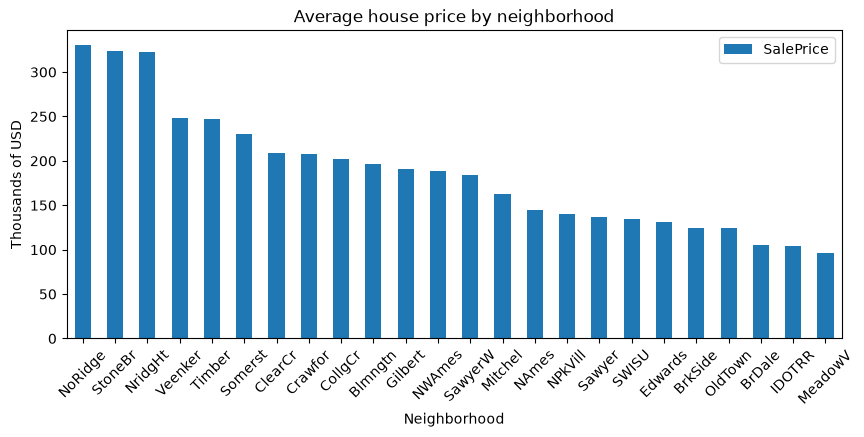

In [85]:
group.plot.bar(
    title='Average house price by neighborhood',
    ylabel='Thousands of USD',
    figsize=(10, 4),
    rot=45,
)

In [86]:
# Part 3
deviation = df_ames.groupby('Neighborhood')
deviation = deviation.std().sort_values(by='SalePrice', ascending=False)
deviation.head(3)

,SalePrice
Neighborhood,
StoneBr,119.270897
NoRidge,101.444018
NridgHt,95.934020


<Axes: title={'center': 'Average hous price vs. standard diviation by neighborhood'}, xlabel='Average hous price (1000 USD)', ylabel='Standard deviation (1000 USD)'>

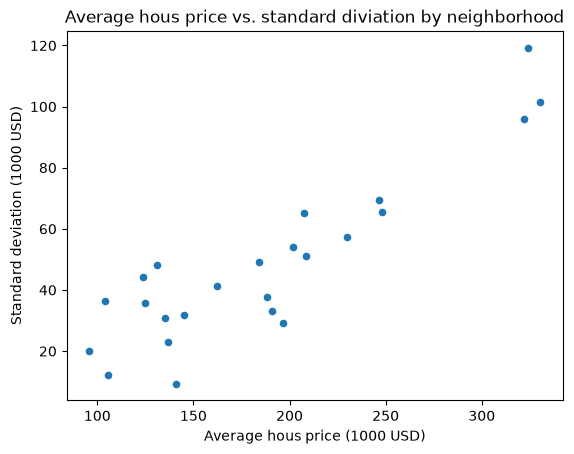

In [87]:
# Part 4
deviation['Average'] = group['SalePrice']
deviation.plot.scatter(
    x='Average', 
    y='SalePrice', 
    title='Average hous price vs. standard diviation by neighborhood',
    xlabel='Average hous price (1000 USD)',
    ylabel='Standard deviation (1000 USD)',
)

In [88]:
# Part 5
deviation['Relative'] = deviation['SalePrice'] / deviation['Average'] * 100

<Axes: title={'center': 'Average hous price vs. relative standard diviation by neighborhood'}, xlabel='Average hous price (1000 USD)', ylabel='Relative standard deviation (1000 USD)'>

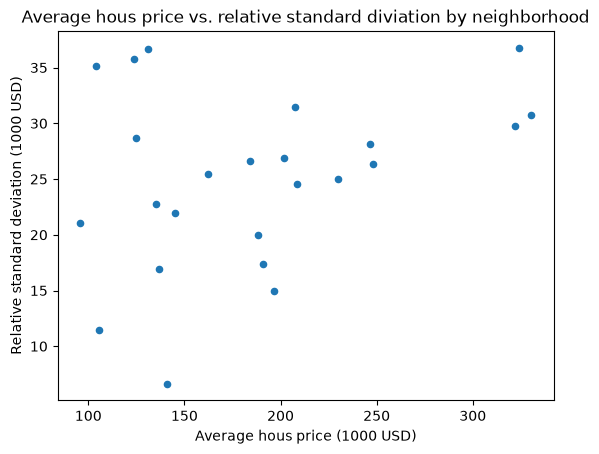

In [89]:
deviation.plot.scatter(
    x='Average', 
    y='Relative', 
    title='Average hous price vs. relative standard diviation by neighborhood',
    xlabel='Average hous price (1000 USD)',
    ylabel='Relative standard deviation (1000 USD)',
)

***
# Exercise 3: Determinants of house prices

For this exercise, we're using data on around 3,000 observations of house prices and house characteristics from Ames, a small city in Iowa,
to understand how house prices vary with selected house characteristics.

1.  Load the Ames housing data set from `ames_houses.csv` located in the `data/` folder.

    Keep only the columns `SalePrice` (price in thousands of US dollars), `LotArea` (lot area in m²), `YearBuilt`, and `Bedrooms` (number of bedrooms).

    Restrict your data set to houses with one or more bedrooms and a lot area of at least 100m². 
    Report the sample size after applying these restrictions.

2.  Compute the average year in which a house was built (using the column `YearBuilt`). 

    Classify houses as _"newer"_ if they were built after the sample's average
    construction year, and _"older"_ otherwise. Store this classification in a new
    column `Newer`, with 1 for newer houses and 0 for older houses.

    What is the average year of construction within these two categories?

3.  Create a new column `Rooms` which categorizes the number of `Bedrooms` into
    three groups: 1–2, 3, and 4 or more. Use the values 2, 3, and 4 to represent
    these groups. You can create these categories using boolean indexing,
    [`np.where()`](https://numpy.org/doc/2.0/reference/generated/numpy.where.html),
    pandas's
    [`where()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.where.html),
    [`map()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html),
    [`clip()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.clip.html),
    or some other way.

4.  Compute the mean sale price and number of observations within each group
    formed by `Newer` and `Rooms` (for a total of 6 different categories).

    By how much does the average price of newer houses with 4+ bedrooms exceed that
    of older houses with 1–2 bedrooms?

5.  Create a figure with two subplots arranged in two columns. The left column
    should contain a bar chart showing the average house price by the number of
    bedrooms (1–2, 3, 4+) for _older_ houses, whereas the right column should show the
    corresponding bars for _newer_ houses. Use a shared vertical scale so that prices
    can be compared across the two panels.

In [102]:
# Part 1
file = f'{DATA_PATH}/ames_houses.csv'
df = pd.read_csv(file, usecols=['SalePrice', 'LotArea', 'YearBuilt', 'Bedrooms'])
df = df[(df['Bedrooms'] >= 1) & (df['LotArea'] >= 100)]

In [103]:
# Part 2
average = df['YearBuilt'].mean().round(1)

df['Newer'] = (df['YearBuilt'] >= average).astype(int)

In [104]:
df.groupby('Newer')['YearBuilt'].mean().round(1)

Newer
0    1945.1
1    1995.7
Name: YearBuilt, dtype: float64

In [107]:
# Part 3
import numpy as np

df['Rooms'] = np.where(
    df['Bedrooms'] <= 2, 2,
    np.where(df['Bedrooms'] >= 4, 4, df['Bedrooms'])
)
df.head(3)

,LotArea,YearBuilt,Bedrooms,SalePrice,Newer,Rooms
0,2951.2,1960,3,215.0,0,3
1,1079.6,1961,2,105.0,0,2
2,1325.3,1958,3,172.0,0,3


In [108]:
# Part 4
newer = df.groupby('Newer')['SalePrice'].mean().round(1)
newer

Newer
0    137.3
1    221.1
Name: SalePrice, dtype: float64

In [109]:
rooms = df.groupby('Rooms')['SalePrice'].mean().round(1)
rooms

Rooms
2    164.9
3    179.7
4    212.8
Name: SalePrice, dtype: float64

In [110]:
# Compute mean house prices and observation counts within each category
df_price_stats = df.groupby(['Newer', 'Rooms'])['SalePrice'].agg(['mean', 'count'])

# Retain the mean prices for the comparison and plots below
mean_prices = df_price_stats['mean']
df_price_stats.round(1)

mean  count
Newer Rooms              
0     2      116.0    427
      3      141.3    727
      4      161.4    254
1     2      213.6    428
      3      211.8    870
      4      273.2    216

In [111]:
# Mean price of newer houses with 4+ bedrooms minus older houses with 1–2 bedrooms
diff = mean_prices.loc[1, 4] - mean_prices.loc[0, 2]

print(
    'Mean price difference (newer 4+ bedrooms minus older 1–2 bedrooms): '
    f'{diff:,.1f} thousand USD'
)

Mean price difference (newer 4+ bedrooms minus older 1–2 bedrooms): 157.1 thousand USD


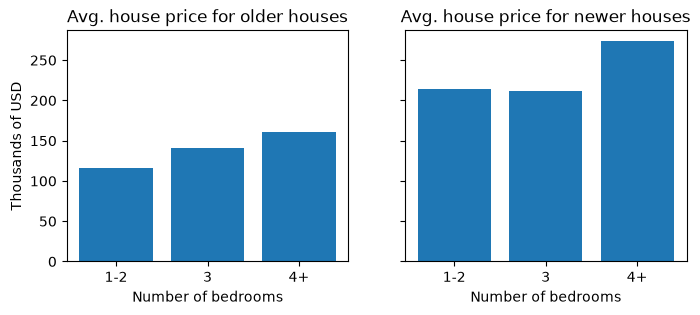

In [114]:
# Part 5
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True)

xvalues = ['1-2', '3', '4+']

axes[0].bar(xvalues, mean_prices.loc[0])
axes[0].set_title('Avg. house price for older houses')
axes[0].set_ylabel('Thousands of USD')
axes[0].set_xlabel('Number of bedrooms')

axes[1].bar(xvalues, mean_prices.loc[1])
axes[1].set_title('Avg. house price for newer houses')
_ = axes[1].set_xlabel('Number of bedrooms')

***
# Exercise 4: Inflation and unemployment in the US

In this exercise, you'll be working with selected macroeconomic variables for the United States reported at monthly frequency obtained from [FRED](https://fred.stlouisfed.org/).
The data set starts in 1948 and contains observations for a total of 936 months.

1.  Load the data from the file `FRED_monthly.csv` located in the `data/FRED`
    folder. Parse `DATE` as dates and use it as the DataFrame index. Sort the
    observations in chronological order, then print the first 10 observations to
    get an idea of what the data looks like.

    Keep only the columns `Year`, `Month`, `CPI`, and `UNRATE`, retaining the date
    index. Perform this analysis only on observations prior to 1970 and drop the
    rest, leaving the sample period 1948–1969.

2.  The column `CPI` stores the consumer price index (CPI) for the US.
    Create a new column `Inflation` which contains _year-over-year inflation in
    percent_: the percent change in the CPI relative to the same month in the
    previous year. Apply
    [`pct_change()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pct_change.html)
    to the column `CPI`.

    *Hints:*

    -   Since this is monthly data, pass `periods=12` to `pct_change()` to get
        year-over-year changes.
    -   Multiply the values returned by `pct_change()` by 100 to get percent
        values.

3.  Compute the average unemployment rate (column `UNRATE`) over the restricted
    1948–1969 sample. Create a new column `UNRATE_HIGH` that contains an indicator
    whenever the unemployment rate is above its average value
    (_"high unemployment period"_).

    -   How many observations fall into the high- and low-unemployment periods?
    -   What is the average unemployment rate in the high- and low-unemployment periods?

4.  Compute the average year-over-year inflation rate for high- and
    low-unemployment periods using the available observations. Is there any
    difference?

    Visualize this relationship by creating a scatter plot with the unemployment rate on the $x$-axis and inflation on the $y$-axis, and assign different colors 
    to observations from the low- and high-unemployment periods.

5.  Use 
    [`resample()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html)
    to compute the calendar-year average of the monthly year-over-year inflation
    rates.

    -   Report the three years with the highest averages.
    -   Create a plot that shows these calendar-year averages over the sample period.

    *Hint:* Use the resampling rule `'YE'` when calling `resample()`.

In [137]:
# Part 1
file = f'{DATA_PATH}/FRED/FRED_monthly.csv'
df = pd.read_csv(file, parse_dates=['DATE'], index_col='DATE')
df = df.sort_index()
df.head()

,Year,Month,CPI,UNRATE,FEDFUNDS,REALRATE,LFPART
DATE,,,,,,,
1948-01-01,1948,1,23.7,3.4,NaN,NaN,58.6
1948-02-01,1948,2,23.7,3.8,NaN,NaN,58.9
1948-03-01,1948,3,23.5,4.0,NaN,NaN,58.5
1948-04-01,1948,4,23.8,3.9,NaN,NaN,59.0
1948-05-01,1948,5,24.0,3.5,NaN,NaN,58.3


In [138]:
df = df[['Year', 'Month', 'CPI', 'UNRATE']]
df = df.query('Year < 1970')

print(f'Number of observations in final sample: {len(df):,d}')

Number of observations in final sample: 264


In [139]:
# Part 2
df['Inflation'] = df['CPI'].pct_change(periods=12) * 100
df

,Year,Month,CPI,UNRATE,Inflation
DATE,,,,,
1948-01-01,1948,1,23.7,3.4,NaN
1948-02-01,1948,2,23.7,3.8,NaN
1948-03-01,1948,3,23.5,4.0,NaN
1948-04-01,1948,4,23.8,3.9,NaN
1948-05-01,1948,5,24.0,3.5,NaN
...,...,...,...,...,...
1969-08-01,1969,8,36.9,3.5,5.428571
1969-09-01,1969,9,37.1,3.7,5.698006
1969-10-01,1969,10,37.3,3.7,5.665722


In [142]:
# Part 3
avg_unrate = df['UNRATE'].mean()

df['UNRATE_HIGH'] = df['UNRATE'] > avg_unrate

df['UNRATE_HIGH'].value_counts()

UNRATE_HIGH
False    141
True     123
Name: count, dtype: int64

In [145]:
df.groupby('UNRATE_HIGH')['UNRATE'].mean()

UNRATE_HIGH
False    3.697872
True     5.781301
Name: UNRATE, dtype: float64

In [146]:
# Part 4
df.groupby('UNRATE_HIGH')['Inflation'].mean()

UNRATE_HIGH
False    3.110456
True     0.942056
Name: Inflation, dtype: float64

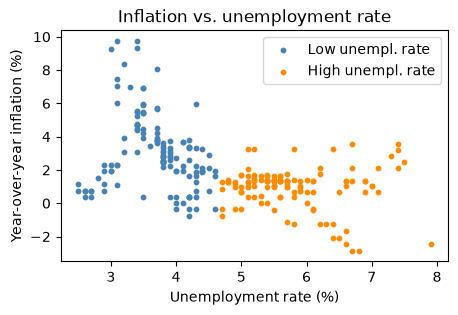

In [149]:
import matplotlib.pyplot as plt

df_hi = df.loc[df['UNRATE_HIGH']]
df_lo = df.loc[~df['UNRATE_HIGH']]

plt.figure(figsize=(5, 3))
plt.scatter(
    df_lo['UNRATE'],
    df_lo['Inflation'],
    label='Low unempl. rate',
    color='steelblue',
    s=10,
)

plt.scatter(
    df_hi['UNRATE'],
    df_hi['Inflation'],
    label='High unempl. rate',
    color='darkorange',
    s=10,
)

plt.xlabel('Unemployment rate (%)')
plt.ylabel('Year-over-year inflation (%)')
plt.title('Inflation vs. unemployment rate')
_ = plt.legend()

In [153]:
# Part 5
groups = df.resample('YE')

infl_avg = groups['Inflation'].mean()

infl_avg.sort_values(ascending=False).head(3)

DATE
1951-12-31    7.987456
1969-12-31    5.432647
1968-12-31    4.241319
Name: Inflation, dtype: float64

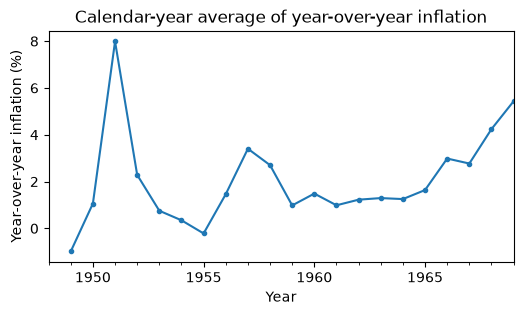

In [154]:
_ = infl_avg.plot.line(
    xlabel='Year',
    ylabel='Year-over-year inflation (%)',
    title='Calendar-year average of year-over-year inflation',
    figsize=(6, 3),
    marker='o',
    ms=3,
)

***
# Exercise 5: From ship arrivals to seasonal traffic

In this exercise, you're asked to aggregate individual ship arrivals to compare
vessel categories and seasonal traffic patterns. For this, we're using data from
Kystverket on reported arrivals at Bergen harbor for the complete calendar years
2013–2025. Each row represents one arrival, including repeat visits by the same
ship.

The file `kystverket/bergen_arrivals.csv.gz` contains four columns:

- `arrival`: Reported arrival time in Bergen local time.
- `vessel_type`: Detailed vessel type.
- `vessel_category`: Broad vessel category, such as passenger ships or
  cargo ships.
- `gross_tonnage`: Gross tonnage (GT), a measure of vessel size based on
  enclosed volume.

See the [data description](../../data/kystverket/README.md) for details.
Note that the extension `.csv.gz` indicates that the file is compressed in order to reduce the file size.

Run the supplied loading cell, then complete these tasks:

1.  Display the first five rows and report the total number of arrivals.

2.  Count arrivals by `vessel_category` and calculate each category's percentage
    of all arrivals. Display the results in descending order of arrival counts
    and create a horizontal bar chart of the counts.

    *Hint:* Use
    [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.sort_values.html)
    to sort the arrival counts.

    *Hint:* You can use either `plt.barh()` or `DataFrame.plot.barh()` to create the bar chart.

3.  Compute the mean `gross_tonnage` for each `vessel_category`. Display all
    categories in descending order of mean gross tonnage and create a horizontal
    bar chart of these means.

4.  Count arrivals in each month separately for `Passenger ships` and
    `Cargo ships`. Store the results in a DataFrame named `df_monthly`, with one
    column per category, and plot both monthly series in one line chart.

    *Hint:* There are several ways to implement this. One way is to compute the monthly counts for each category separately and then combine the results into a single DataFrame.

5.  Use `groupby()` to calculate average monthly arrivals for each calendar
    month, from January through December. Create two seasonal bar charts, one
    per category, with a shared vertical scale. Describe the contrast in one
    sentence.

    *Hint:* Group `df_monthly` by `df_monthly.index.month`. Replace the resulting index with the supplied `month_names`. 
    
    *Hint:* Use
    `plot.bar(subplots=True, layout=(1, 2), sharey=True)` for the two panels when plotting with the pandas plotting API.


In [ ]:
# Part 1
import pandas as pd

# Relative path to the data directory
DATA_PATH = '../../data'
# Path to the compressed Bergen arrivals CSV file
file = f'{DATA_PATH}/kystverket/bergen_arrivals.csv.gz'

# Parse arrival times and prepare a chronological date index
df_arrivals = pd.read_csv(file, parse_dates=['arrival'], index_col='arrival')

# Sort arrivals in chronological order
df_arrivals = df_arrivals.sort_index()

# Labels for the seasonal bar charts
month_names = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec',
]

In [155]:
print(f'Number of arrivals: {len(df_arrivals):,}')
df_arrivals.head(5)

Number of arrivals: 45,620


,vessel_type,vessel_category,gross_tonnage
arrival,,,
2013-01-01 03:00:00,Platform Supply Ship,Offshore and special-purpose vessels,3350.0
2013-01-01 12:10:00,Diving Support Vessel,Offshore and special-purpose vessels,7502.0
2013-01-01 19:00:00,Offshore Support Vessel,Offshore and special-purpose vessels,8552.0
2013-01-02 01:00:00,Offshore Support Vessel,Offshore and special-purpose vessels,8552.0
2013-01-02 03:45:00,Tug,Offshore and special-purpose vessels,370.0


In [157]:
# Part 2
counts = df_arrivals.groupby('vessel_category').size()
counts = counts.sort_values(ascending=False)

shares = 100 * counts / counts.sum()

df_categories = pd.DataFrame({'arrivals': counts, 'share_percent': shares})
df_categories.round(1)

,arrivals,share_percent
vessel_category,,
Cargo ships,17799,39.0
Offshore and special-purpose vessels,12953,28.4
Passenger ships,10141,22.2
Tankers,3488,7.6
Fishing vessels,995,2.2
Unknown,194,0.4
Recreational vessels,50,0.1


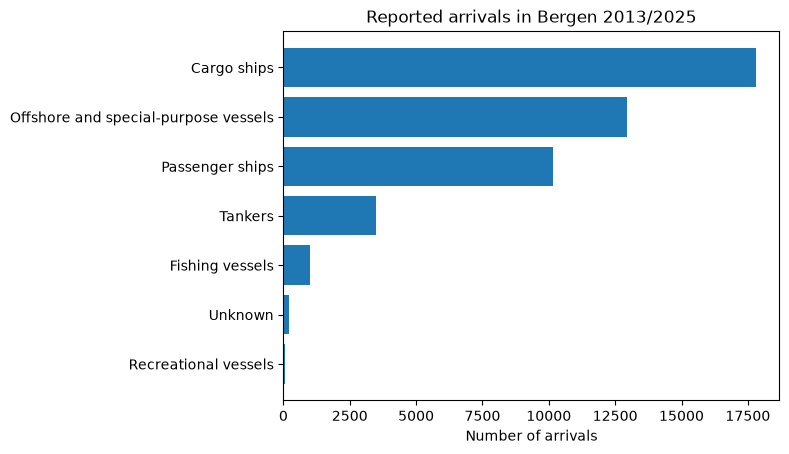

In [158]:
import matplotlib.pyplot as plt

counts_ascending = counts.sort_values()

plt.barh(counts_ascending.index, counts_ascending)
plt.title('Reported arrivals in Bergen 2013/2025')
_ = plt.xlabel('Number of arrivals')

In [161]:
# Part 3
avg_tonn = df_arrivals.groupby('vessel_category')['gross_tonnage'].mean().sort_values(ascending=False)
avg_tonn

vessel_category
Passenger ships                         36060.081294
Cargo ships                              5156.656160
Offshore and special-purpose vessels     4862.774166
Tankers                                  2171.372133
Fishing vessels                          1636.176884
Unknown                                  1120.031088
Recreational vessels                       95.306122
Name: gross_tonnage, dtype: float64

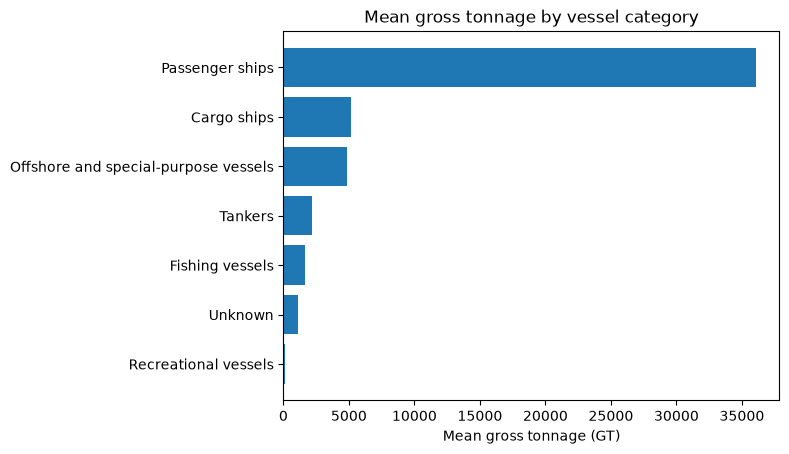

In [164]:
avg_tonn = avg_tonn.sort_values(ascending=True)

plt.barh(avg_tonn.index, avg_tonn)
plt.title('Mean gross tonnage by vessel category')
_ = plt.xlabel('Mean gross tonnage (GT)')

In [166]:
# Part 4
categories = ['Passenger ships', 'Cargo ships']

df_monthly = df_arrivals.groupby('vessel_category').resample('ME').size()

df_monthly = df_monthly.unstack(level='vessel_category')

df_monthly = df_monthly[categories]
df_monthly.head()

vessel_category,Passenger ships,Cargo ships
arrival,,
2013-01-31,10.0,137.0
2013-02-28,16.0,132.0
2013-03-31,18.0,149.0
2013-04-30,20.0,156.0
2013-05-31,65.0,177.0


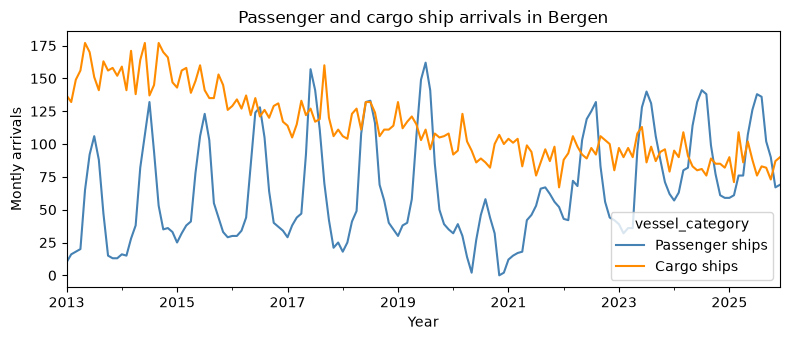

In [167]:
df_monthly.plot.line(
    figsize=(8, 3.5),
    xlabel='Year',
    ylabel='Montly arrivals',
    title='Passenger and cargo ship arrivals in Bergen',
    color=['steelblue', 'darkorange'],
    linewidth=1.5,
)
plt.tight_layout()

In [168]:
# Part 5
df_seasonal = df_monthly.groupby(df_monthly.index.month).mean()
df_seasonal.index = month_names
df_seasonal.round(1)

vessel_category,Passenger ships,Cargo ships
Jan,30.8,114.3
Feb,34.3,109.5
Mar,42.6,123.7
Apr,45.5,115.5
May,82.9,118.3
Jun,111.2,119.5
Jul,120.6,108.8
Aug,109.2,108.2
Sep,72.6,116.2
Oct,52.9,114.3


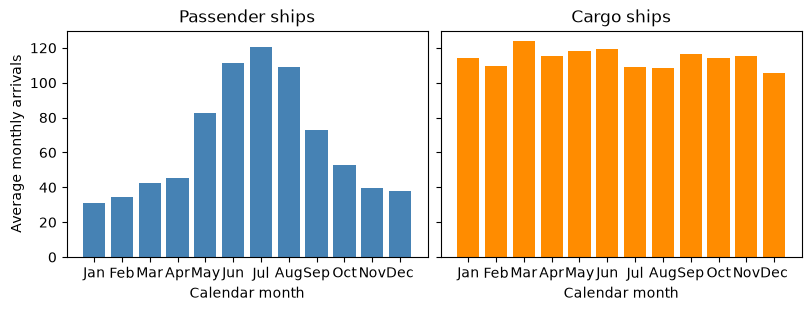

In [169]:
fig, axes = plt.subplots(
    1, 2, figsize=(8, 3), sharey=True, layout='constrained'
)

axes[0].bar(df_seasonal.index, df_seasonal['Passenger ships'], color='steelblue')
axes[0].set_title('Passender ships')
axes[0].set_ylabel('Average monthly arrivals')
axes[0].set_xlabel('Calendar month')

axes[1].bar(df_seasonal.index, df_seasonal['Cargo ships'], color='darkorange')
axes[1].set_title('Cargo ships')
_ = axes[1].set_xlabel('Calendar month')